# 07 · NEON feasibility: Harvard Forest (HARV), July 2023

**Scope.** Exploratory public-data feasibility only (independent review 2: GO for feasibility, no confirmatory E2 claims). One site, one month. The questions are whether the camera, the label probe and an independent conditioning thermometer can be joined on a verified common clock, and what the data quality and physics problems are. No model is fitted and no visual feature is computed.

The site and month were fixed by coverage (notebook 02), before any humidity value was inspected. Data come from the NEON Data Portal API (authenticated with the token in `.env`, which never enters the notebook) and the PhenoCam archive (CC BY 4.0). Raw files are kept in `data/raw/` and stay out of Git.

| product | role in the data contract |
|---|---|
| DP1.00098.001 RH, tower top (HMP155) | label: `rh_ref_pct`, `temp_ref_c` → `td_ref_c`, `d_ref_k` |
| DP1.00003.001 triple-aspirated air temperature, tower top | conditioning: `temp_cond_c` |
| DP1.00023.001 shortwave/longwave radiation, tower top | QC: radiation-error diagnostics (`met`) |
| DP1.00033.001 phenology camera (PhenoCam archive, 30-min RGB) | frames: `frame_ids`, with `.meta` camera settings |

In [1]:
import datetime as dt
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from visual_hygrometry import neon, thermo

plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (10, 3.2), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.precision', 3, 'display.max_colwidth', 70)
SITE, MONTH, CAM, UTC_OFFSET = 'HARV', '2023-07', 'NEON.D01.HARV.DP1.00033', -5

## 1 · Downloads and provenance

Each download is idempotent and recorded with SHA-256. Only the tower-top (`000.060`) 1-min basic package is used. The full set of `.meta` files is kept, plus a JPEG sample: every noon frame and all frames of 10 and 24 July. Those days were chosen by date before any data were inspected.

In [2]:
man = pd.concat([neon.neon_files(p, SITE, MONTH, pat) for p, pat in [
    ('DP1.00098.001', r'(000\.060\.001\.RH_1min|sensor_positions|variables|readme)'),
    ('DP1.00003.001', r'(000\.060\.001\.TAAT_1min|sensor_positions|variables|readme)'),
    ('DP1.00023.001', r'(000\.060\.001\.SLRNR_1min|sensor_positions|variables|readme)')]], ignore_index=True)
cam_dir = neon.RAW / 'phenocam' / CAM / MONTH
listing = cam_dir / 'listing.csv'
if not listing.exists():
    pd.DataFrame([(d.date(), b) for d in pd.date_range(f'{MONTH}-01', f'{MONTH}-31') for b in neon.camera_day(CAM, d)], columns=['day', 'base']).to_csv(listing, index=False)
frames = pd.read_csv(listing)
for b in frames.base: neon.fetch(neon.archive_url(CAM, b, 'meta'), cam_dir / f'{b}.meta', pause=0.02)
sample = set(frames.base[frames.base.str.endswith(('_120004', '_120005'))]) | set(frames.base[frames.day.isin(['2023-07-10', '2023-07-24'])])
for b in sorted(sample): neon.fetch(neon.archive_url(CAM, b, 'jpg'), cam_dir / f'{b}.jpg', pause=0.05)
print(f'NEON files: {len(man)}, {man.bytes.sum() / 1e6:.1f} MB | frames listed: {len(frames)} | meta files: {len(list(cam_dir.glob("*.meta")))} | JPEG sample: {len(sample)} '
      f'({sum((cam_dir / f"{b}.jpg").stat().st_size for b in sample) / 1e6:.0f} MB)')
man.assign(sha256=man.sha256.str[:12])[['product', 'name', 'bytes', 'sha256']]

NEON files: 12, 20.9 MB | frames listed: 1082 | meta files: 1082 | JPEG sample: 97 (56 MB)


,product,name,bytes,sha256
0,DP1.00098.001,NEON.D01.HARV.DP1.00098.001.sensor_positions.20230809T214353Z.csv,844,5e3cc9e4d2b3
1,DP1.00098.001,NEON.D01.HARV.DP1.00098.001.variables.20230809T214353Z.csv,40006,e9e8a2b4a1b6
2,DP1.00098.001,NEON.D01.HARV.DP1.00098.001.000.060.001.RH_1min.2023-07.basic.2023...,7622767,244c615a25d2
3,DP1.00098.001,NEON.D01.HARV.DP1.00098.001.readme.20260123T000749Z.txt,13866,da0824807dd8
4,DP1.00003.001,NEON.D01.HARV.DP1.00003.001.readme.20260123T000749Z.txt,12326,8949114f5383
5,DP1.00003.001,NEON.D01.HARV.DP1.00003.001.sensor_positions.20241121T021115Z.csv,882,226998284a74
6,DP1.00003.001,NEON.D01.HARV.DP1.00003.001.variables.20241121T021115Z.csv,21888,93a412344b00
7,DP1.00003.001,NEON.D01.HARV.DP1.00003.001.000.060.001.TAAT_1min.2023-07.basic.20...,4503003,68c4bba73a6f
8,DP1.00023.001,NEON.D01.HARV.DP1.00023.001.variables.20230810T000112Z.csv,54235,6b2e5c97c274
9,DP1.00023.001,NEON.D01.HARV.DP1.00023.001.000.060.001.SLRNR_1min.2023-07.basic.2...,8630316,cbb845ab3258


## 2 · Sensor geometry

In [3]:
pos = pd.concat([pd.read_csv(p, dtype={'HOR.VER': str}).assign(product=p.name.split('.')[4]) for p in man.path if 'sensor_positions' in str(p)])
top = pos[pos['HOR.VER'].astype(str).str.fullmatch(r'0*0\.060|000\.060')].drop_duplicates('product', keep='last')[['product', 'sensorLocationDescription', 'xOffset', 'yOffset', 'zOffset']]
top['horizontal_from_RH_m'] = np.hypot(top.xOffset - top.xOffset.iloc[0], top.yOffset - top.yOffset.iloc[0])
top['vertical_from_RH_m'] = top.zOffset - top.zOffset.iloc[0]
top

,product,sensorLocationDescription,xOffset,yOffset,zOffset,horizontal_from_RH_m,vertical_from_RH_m
0,00098,"Harvard Forest Relative Humidity, Tower",-0.52,-0.89,38.63,0.000,0.00
1,00003,Harvard Forest Triple Aspirated Air Temperature L6,1.83,5.16,38.39,6.490,-0.24
0,00023,Harvard Forest Net Radiation Southwest,1.83,5.98,39.10,7.261,0.47


The label probe and the aspirated thermometer are on the same tower top, 0.24 m apart vertically and ~6.5 m horizontally. The camera is also mounted at the tower top (NEON product description). Its position relative to the probes is not in these files and remains unverified.

## 3 · Sensor tables, missingness and quality flags

In [4]:
read = lambda key: pd.read_csv(next(p for p in man.path if key in str(p)), parse_dates=['startDateTime', 'endDateTime'])
rh, taat, rad = read('RH_1min'), read('TAAT_1min'), read('SLRNR_1min')
minutes = pd.date_range(f'{MONTH}-01', periods=31 * 1440, freq='1min', tz='UTC')
qc = pd.DataFrame({name: {'rows': len(t), 'value present': t[v].notna().mean(), 'final QF = 0': (t[q] == 0).mean(), 'usable (present & QF 0)': (t[v].notna() & (t[q] == 0)).mean()}
                   for name, t, v, q in [('RH (HMP155)', rh, 'RHMean', 'RHFinalQF'), ('T of RH probe', rh, 'tempRHMean', 'tempRHFinalQF'),
                                         ('aspirated T', taat, 'tempTripleMean', 'finalQF'), ('incoming SW', rad, 'inSWMean', 'inSWFinalQF')]}).T
print(f'expected minutes: {len(minutes)}')
qc

expected minutes: 44640


,rows,value present,final QF = 0,usable (present & QF 0)
RH (HMP155),44640.0,0.967,0.966,0.966
T of RH probe,44640.0,0.997,0.997,0.997
aspirated T,44640.0,0.997,0.996,0.996
incoming SW,44640.0,0.997,0.997,0.997


In [5]:
s = (rh.set_index('startDateTime')[['RHMean', 'RHExpUncert', 'RHFinalQF', 'tempRHMean', 'tempRHFinalQF', 'dewTempMean', 'dewTempFinalQF']]
     .join(taat.set_index('startDateTime')[['tempTripleMean', 'finalQF']], how='outer')
     .join(rad.set_index('startDateTime')[['inSWMean', 'inSWFinalQF']], how='outer').reindex(minutes))
ok = s[['RHFinalQF', 'tempRHFinalQF', 'finalQF']].eq(0).all(axis=1) & s[['RHMean', 'tempRHMean', 'tempTripleMean']].notna().all(axis=1)
daily = ok.groupby(ok.index.tz_convert(None).floor('D')).mean()
print(f'minutes with usable label and conditioning temperature: {ok.mean():.1%}; days below 90 %: {(daily < .9).sum()}')

minutes with usable label and conditioning temperature: 96.5%; days below 90 %: 4


## 4 · Physical label construction

`td_ref_c` comes from the probe's own RH and temperature (Magnus over water, `thermo.dewpoint`), and `d_ref_k = temp_ref_c − td_ref_c`. NEON's `dewTempMean` is an independent check of the formula. The censoring limit comes from the instrument uncertainty that NEON reports per minute: σ_RH = `RHExpUncert`/2 (expanded uncertainty, coverage factor 2), RH_c = 100 − σ_RH (`thermo.label_d`). It is never set from the label distribution.

In [6]:
L = s[ok].copy()
L['td'] = thermo.dewpoint(L.tempRHMean, L.RHMean)
L['rh_c'] = 100 - L.RHExpUncert / 2
L['d'], L['censored'] = thermo.label_d(L.tempRHMean, L.RHMean, L.rh_c)
dtd = L.td - L.dewTempMean
print(f'Magnus Td - NEON dewTempMean: mean {dtd.mean():+.3f} K, 99 % of |diff| < {dtd.abs().quantile(.99):.3f} K')
print(f'sigma_RH from NEON: median {(L.RHExpUncert / 2).median():.2f} %RH (range {(L.RHExpUncert / 2).min():.2f}-{(L.RHExpUncert / 2).max():.2f}); censored minutes: {L.censored.mean():.1%}')
L[['RHMean', 'tempRHMean', 'tempTripleMean', 'td', 'd']].describe(percentiles=[.01, .5, .99]).T

Magnus Td - NEON dewTempMean: mean +0.046 K, 99 % of |diff| < 0.051 K
sigma_RH from NEON: median 1.14 %RH (range 1.14-1.66); censored minutes: 0.0%


,count,mean,std,min,1%,50%,99%,max
RHMean,43092.0,78.752,16.715,30.870,42.240,82.580,98.550,99.020
tempRHMean,43092.0,21.837,3.456,11.736,13.999,21.530,29.670,32.925
tempTripleMean,43092.0,21.492,3.148,11.812,13.918,21.270,28.231,29.584
td,43092.0,17.566,2.985,6.729,9.424,18.210,21.818,23.029
d,43092.0,4.271,3.767,0.179,0.232,3.074,13.795,18.664


**Near saturation.** A humid forest month should contain fog and dew nights at RH ≈ 100 %, and frames in §8 show fog. The checks below ask whether the probe resolves them.

minutes with RH >= 97 %: 13.0%; >= 98 %: 6.1%; >= 99 %: 0.00%; max 99.02 %
censored by the per-minute instrument rule: 5 minutes; with the HMP155 90-100 %RH specification (1.7 %RH as one SD, limit 98.3 %): 3.3%


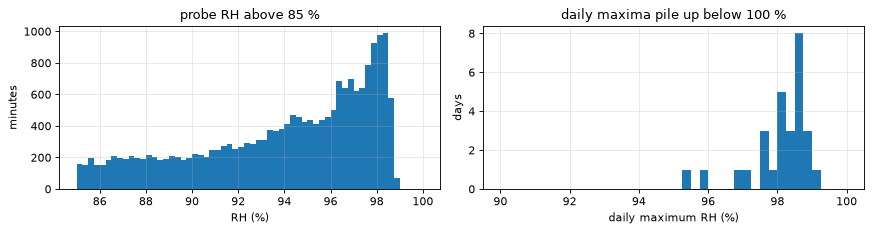

In [7]:
print(f'minutes with RH >= 97 %: {(L.RHMean >= 97).mean():.1%}; >= 98 %: {(L.RHMean >= 98).mean():.1%}; >= 99 %: {(L.RHMean >= 99).mean():.2%}; max {L.RHMean.max():.2f} %')
print(f'censored by the per-minute instrument rule: {int(L.censored.sum())} minutes; with the HMP155 90-100 %RH specification (1.7 %RH as one SD, limit 98.3 %): {(L.RHMean >= 98.3).mean():.1%}')
night_max = L.RHMean.groupby(L.index.tz_convert('Etc/GMT+5').date).max()
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(L.RHMean[L.RHMean > 85], bins=np.arange(85, 100.01, 0.25)); ax[0].set(xlabel='RH (%)', ylabel='minutes', title='probe RH above 85 %')
ax[1].hist(night_max, bins=np.arange(90, 100.01, 0.25)); ax[1].set(xlabel='daily maximum RH (%)', ylabel='days', title='daily maxima pile up below 100 %')
plt.tight_layout(); plt.show()

## 5 · Temperature disagreement and radiation error

The HMP155 temperature (`tempRHMean`) and the triple-aspirated PRT measure the same air ~6.5 m apart. If the probe's shield is not aspirated, sunshine heats it. Notebook 00 §4 showed that a heated probe reports the correct dew point but a `D` that is too high by exactly the heating, and notebook 01 §9 showed that such an error, if visible to the camera, creates spurious E2. The difference is examined against incoming shortwave radiation.

HMP155 - aspirated T: night mean +0.060 K, day mean +0.545 K, slope +0.077 K per 100 W m-2


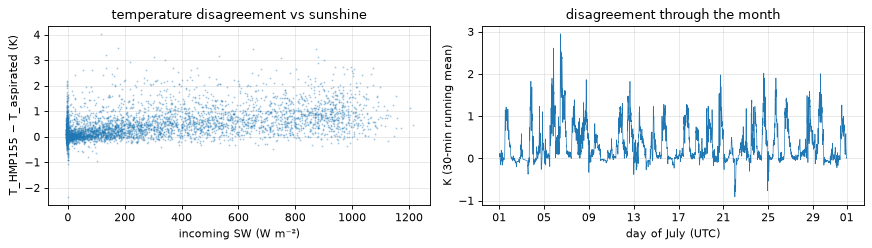

,count,mean,5%,50%,95%
sw_bin,,,,,
"(-50, 10]",17806.0,0.060,-0.184,0.014,0.527
"(10, 100]",5438.0,0.167,-0.174,0.071,0.854
"(100, 300]",6485.0,0.408,-0.098,0.284,1.419
"(300, 500]",4149.0,0.652,-0.063,0.544,1.780
"(500, 700]",3230.0,0.740,-0.022,0.639,1.943
"(700, 900]",3263.0,0.827,0.008,0.750,1.942
"(900, 1400]",2718.0,0.897,0.006,0.824,2.025


In [8]:
L['dT'] = L.tempRHMean - L.tempTripleMean
L['sw_bin'] = pd.cut(L.inSWMean, [-50, 10, 100, 300, 500, 700, 900, 1400])
tab = L.groupby('sw_bin', observed=True).dT.describe(percentiles=[.05, .5, .95])[['count', 'mean', '5%', '50%', '95%']]
day = L.inSWMean > 10
slope = np.polyfit(L.inSWMean[day], L.dT[day], 1)[0] * 100
print(f'HMP155 - aspirated T: night mean {L.dT[~day].mean():+.3f} K, day mean {L.dT[day].mean():+.3f} K, slope {slope:+.3f} K per 100 W m-2')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(L.inSWMean[::7], L.dT[::7], '.', ms=1.5, alpha=.3); ax[0].set(xlabel='incoming SW (W m⁻²)', ylabel='T_HMP155 − T_aspirated (K)', title='temperature disagreement vs sunshine')
ax[1].plot(L.index[::5], L.dT.rolling(30).mean()[::5], lw=.6); ax[1].set(ylabel='K (30-min running mean)', xlabel='day of July (UTC)', title='disagreement through the month')
ax[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d'))
plt.tight_layout(); plt.show()
tab

In [9]:
L['d_hybrid'] = L.tempTripleMean - L.td  # aspirated T with the probe's dew point (insensitive to probe heating)
print(f'D (probe T) - D (aspirated T, probe dew point): day {(L.d - L.d_hybrid)[day].mean():+.3f} K, night {(L.d - L.d_hybrid)[~day].mean():+.3f} K; '
      f'corr with SW in daytime {np.corrcoef(L.inSWMean[day], (L.d - L.d_hybrid)[day])[0, 1]:+.2f}')
print(f'aspirated T below the probe dew point (D_hybrid < 0, physically impossible without probe offset or wetting): {(L.d_hybrid < 0).mean():.1%} of minutes, '
      f'{(L.d_hybrid < 0)[~day].mean():.1%} of night minutes; min D_hybrid {L.d_hybrid.min():+.2f} K')

D (probe T) - D (aspirated T, probe dew point): day +0.545 K, night +0.060 K; corr with SW in daytime +0.42
aspirated T below the probe dew point (D_hybrid < 0, physically impossible without probe offset or wetting): 0.3% of minutes, 0.4% of night minutes; min D_hybrid -0.88 K


**Observation.** The HMP155 reads warmer than the aspirated PRT by +0.06 K at night and +0.55 K by day. The gap rises steadily with incoming shortwave: median +0.82 K and 95th percentile +2.0 K above 900 W m⁻², slope +0.077 K per 100 W m⁻². This is the signature of a radiatively heated, non-aspirated shield. The readme does not state the shield type, so that interpretation is inferred, not documented.

**Consequences.**
1. The label `D` built from the probe's own temperature carries a sunshine-correlated error of about +0.5 K by day (correlation with SW +0.42). Notebook 01 §9 showed that an error of this kind produces spurious E2 of order 0.01–0.03 nats when the camera can see sunshine, the same order as the illustrative threshold.
2. The aspirated temperature combined with the probe's dew point (`D_hybrid`) removes the heating term, because the probe dew point is insensitive to probe heating to first order. The cost: label and conditioning temperature then share one unit, whose small (±0.15 K expanded) errors become common-mode, and exact D ↔ RH invariance is lost.
3. In 0.3 % of minutes the aspirated temperature lies below the probe dew point (down to −0.88 K), so the units also disagree for reasons unrelated to sunshine.

Which label is primary is a consequential decision (review requested).

## 6 · Frames: availability, clock and camera state

`.meta` files record the camera settings at capture. Their `overlay_text` is the text burned into the image, including a UTC clock and the camera's internal temperature, so every frame's filename time can be checked against an independent UTC stamp.

In [10]:
def meta_row(b):
    m = neon.parse_meta((cam_dir / f'{b}.meta').read_text(errors='replace'))
    o = m.get('overlay_text', '')
    utc = re.search(r'(\w{3} \w{3} \d{1,2} \d{4})\s+(\d{2}:\d{2}:\d{2}) UTC', o)
    temp = re.search(r'Camera Temperature:\s*(-?[\d.]+)', o)
    return dict(base=b, overlay_utc=pd.to_datetime(' '.join(utc.groups()), format='%a %b %d %Y %H:%M:%S', utc=True) if utc else pd.NaT,
                camera_temp_c=float(temp.group(1)) if temp else np.nan, exposure=float(m.get('exposure', 'nan')), overlay=m.get('overlay'),
                auto_exposure=m.get('auto_exposure'), agc=m.get('agc'), auto_haze=m.get('auto_haze'), ir_enable=m.get('ir_enable'), wb_red=m.get('red'), wb_blue=m.get('blue'),
                overlay_pos=f"{m.get('overlay_position')}/{m.get('overlay_x')}/{m.get('overlay_y')}", resolution=m.get('resolution'))

F = frames.merge(pd.DataFrame([meta_row(b) for b in frames.base]), on='base')
F['local'] = pd.to_datetime(F.base.str[-17:], format='%Y_%m_%d_%H%M%S')
F['utc'] = (F.local - pd.Timedelta(hours=UTC_OFFSET)).dt.tz_localize('UTC')
F['clock_offset_s'] = (F.overlay_utc - F.utc).dt.total_seconds()
per_day = F.groupby('day').size()
print(f'frames: {len(F)}; per day median {per_day.median():.0f} (min {per_day.min()}, max {per_day.max()}); days with frames {len(per_day)}/31')
print(f'filename (UTC-5) vs overlay UTC: offset median {F.clock_offset_s.median():.0f} s, max |offset| {F.clock_offset_s.abs().max():.0f} s, unparsable {F.overlay_utc.isna().sum()}')
pd.DataFrame({k: F[k].value_counts().to_dict() for k in ['overlay', 'overlay_pos', 'resolution', 'auto_exposure', 'agc', 'auto_haze', 'ir_enable', 'wb_red', 'wb_blue']}).T

frames: 1082; per day median 35 (min 33, max 36); days with frames 31/31
filename (UTC-5) vs overlay UTC: offset median 0 s, max |offset| 0 s, unparsable 0


,on,0/0/0,6,1,0,385,330
overlay,1082.0,NaN,NaN,NaN,NaN,NaN,NaN
overlay_pos,NaN,1082.0,NaN,NaN,NaN,NaN,NaN
resolution,NaN,NaN,1082.0,NaN,NaN,NaN,NaN
auto_exposure,NaN,NaN,NaN,1082.0,NaN,NaN,NaN
agc,NaN,NaN,NaN,1082.0,NaN,NaN,NaN
auto_haze,NaN,NaN,NaN,1082.0,NaN,NaN,NaN
ir_enable,NaN,NaN,NaN,NaN,1082.0,NaN,NaN
wb_red,NaN,NaN,NaN,NaN,NaN,1082.0,NaN
wb_blue,NaN,NaN,NaN,NaN,NaN,NaN,1082.0


## 7 · The image–sensor join

A frame is matched to the 1-min record whose interval contains its verified UTC capture time. A match is usable when label, conditioning temperature and shortwave all pass QC in that minute. Frames with incoming SW ≤ 10 W m⁻² are flagged as dark (dawn/dusk/night).

frames matched to a 1-min record: 96.7%; usable label + conditioning T: 96.5%; usable and daylit: 77.8% (842 frames)
capture lag within the minute: 4-7 s (median 4 s)


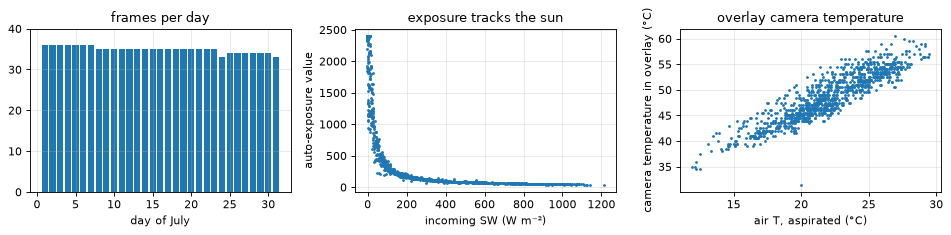

corr(exposure, SW) = -0.64; corr(camera temp, air T) = +0.90; corr(camera temp - air T, SW) = +0.44


In [11]:
F['minute'] = F.utc.dt.floor('1min')
J = F.join(s, on='minute')
J['lag_s'] = (F.utc - F.minute).dt.total_seconds()
J['usable'] = J.minute.isin(L.index)
J['dark'] = J.inSWMean <= 10
print(f'frames matched to a 1-min record: {J.RHMean.notna().mean():.1%}; usable label + conditioning T: {J.usable.mean():.1%}; '
      f'usable and daylit: {(J.usable & ~J.dark).mean():.1%} ({(J.usable & ~J.dark).sum()} frames)')
print(f'capture lag within the minute: {J.lag_s.min():.0f}-{J.lag_s.max():.0f} s (median {J.lag_s.median():.0f} s)')
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].bar(per_day.index.astype(str).str[-2:].astype(int), per_day.values); ax[0].set(title='frames per day', xlabel='day of July', ylim=(0, 40))
ax[1].plot(J.inSWMean, J.exposure, '.', ms=3); ax[1].set(xlabel='incoming SW (W m⁻²)', ylabel='auto-exposure value', title='exposure tracks the sun')
ax[2].plot(J.tempTripleMean, J.camera_temp_c, '.', ms=3); ax[2].set(xlabel='air T, aspirated (°C)', ylabel='camera temperature in overlay (°C)', title='overlay camera temperature')
plt.tight_layout(); plt.show()
print(f'corr(exposure, SW) = {J[["exposure", "inSWMean"]].corr().iloc[0, 1]:+.2f}; corr(camera temp, air T) = {J[["camera_temp_c", "tempTripleMean"]].corr().iloc[0, 1]:+.2f}; '
      f'corr(camera temp - air T, SW) = {np.corrcoef(J.inSWMean.fillna(0), (J.camera_temp_c - J.tempTripleMean).fillna(0))[0, 1]:+.2f}')

## 8 · What the frames look like, and the overlay

Every frame burns three lines into its top-left corner: camera id and **UTC time**, **camera temperature**, and the **auto-exposure value**. Model inputs must never see these pixels, since they carry a clock, a heat proxy and an acquisition setting (`docs/metadata_policy.md`). The mask below was drawn from the 1 July noon frame. The overlay position fields are constant in every `.meta` file (table in §6), so one fixed mask applies to the whole month.

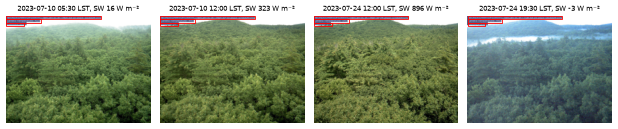

mask covers 3.1% of the frame; image size (1296, 960)


In [12]:
MASK = [(0, 0, 846, 29), (0, 29, 312, 58), (0, 58, 160, 88)]  # (x0, y0, x1, y1) at 1296 x 960
show = [b for b in ['NEON.D01.HARV.DP1.00033_2023_07_10_053004', 'NEON.D01.HARV.DP1.00033_2023_07_10_120004', 'NEON.D01.HARV.DP1.00033_2023_07_24_120004', 'NEON.D01.HARV.DP1.00033_2023_07_24_193004']
        if (cam_dir / f'{b}.jpg').exists()]
fig, ax = plt.subplots(1, len(show), figsize=(2.6 * len(show), 2.2), dpi=60)
for a, b in zip(np.atleast_1d(ax), show):
    im = Image.open(cam_dir / f'{b}.jpg')
    a.imshow(im.resize((im.width // 6, im.height // 6)))
    for x0, y0, x1, y1 in MASK: a.add_patch(plt.Rectangle((x0 / 6, y0 / 6), (x1 - x0) / 6, (y1 - y0) / 6, fill=False, ec='red', lw=1))
    j = J.set_index('base').loc[b]
    a.set_title(f"{b[-17:-7].replace('_', '-')} {b[-6:-4]}:{b[-4:-2]} LST, SW {j.inSWMean:.0f} W m⁻²", fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()
print(f'mask covers {sum((x1 - x0) * (y1 - y0) for x0, y0, x1, y1 in MASK) / (1296 * 960):.1%} of the frame; image size {Image.open(cam_dir / f"{show[0]}.jpg").size}')

**Observation (descriptive only, no feature computed).** The 05:30 frame of 10 July shows fog or low cloud over the ridge; the 19:30 frame of 24 July shows a valley fog layer below it. Moisture phenomena do appear in this scene.

**Constraints for any visual pathway.**
- The thin sky band at the top is largely covered by the overlay.
- The distant ridge is a natural contrast target, but its distance is not surveyed.
- Every frame has auto-exposure, AGC and `auto_haze = 1` (in-camera haze compensation). The camera actively changes the contrast and haze signal an extinction pathway would rely on.
- Only JPEG is available, with unknown tone processing. Radiometric normalisation is limited to the recorded exposure value.

## 9 · Month overview

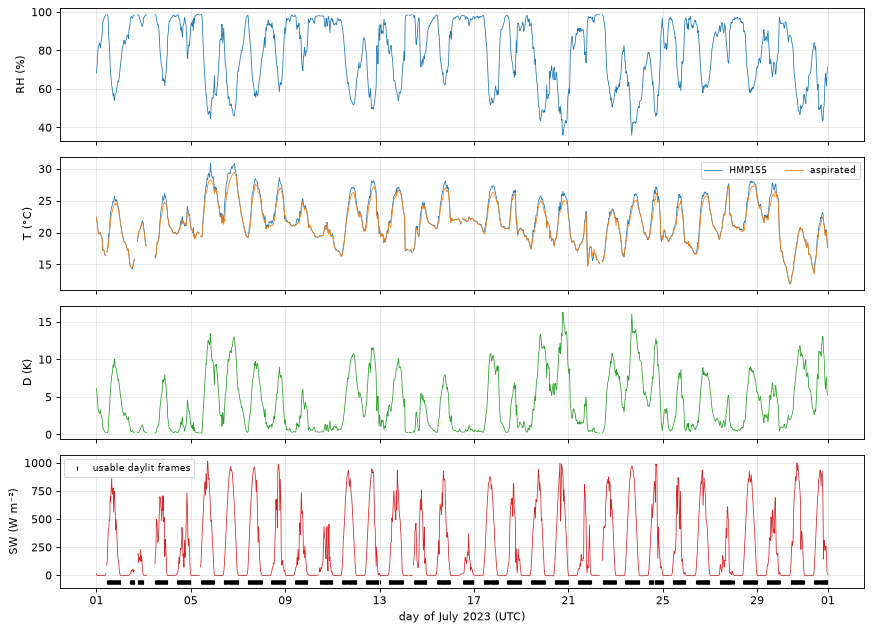

daytime daily-mean D: lag-1 autocorrelation +0.03, lag-2 -0.13 (32 days; a crude estimate of weather persistence)


In [13]:
fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
h = L.resample('30min').mean(numeric_only=True)
ax[0].plot(h.index, h.RHMean, lw=.7); ax[0].set_ylabel('RH (%)')
ax[1].plot(h.index, h.tempRHMean, lw=.7, label='HMP155'); ax[1].plot(h.index, h.tempTripleMean, lw=.7, label='aspirated'); ax[1].set_ylabel('T (°C)'); ax[1].legend(ncol=2, fontsize=8)
ax[2].plot(h.index, h.d, lw=.7, c='C2'); ax[2].set_ylabel('D (K)')
ax[3].plot(h.index, h.inSWMean, lw=.7, c='C3'); ax[3].set_ylabel('SW (W m⁻²)')
ax[3].plot(J.utc[J.usable & ~J.dark], np.full((J.usable & ~J.dark).sum(), -60), '|', c='k', ms=4, label='usable daylit frames'); ax[3].legend(fontsize=8)
for a in ax: a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d'))
ax[3].set_xlabel('day of July 2023 (UTC)')
plt.tight_layout(); plt.show()
dm = L.d[L.inSWMean > 10].groupby(L.index[L.inSWMean > 10].tz_convert('Etc/GMT+5').date).mean()
print(f'daytime daily-mean D: lag-1 autocorrelation {dm.autocorr(1):+.2f}, lag-2 {dm.autocorr(2):+.2f} ({len(dm)} days; a crude estimate of weather persistence)')

## 10 · Feasibility checklist

| item | status | evidence |
|---|---|---|
| clock pairing | **verified** | filename time (UTC−5) equals the burned-in UTC stamp to 0 s in 1082 / 1082 frames; capture 4–7 s into the 1-min record |
| sensor geometry | partly verified | label probe and aspirated PRT on the tower top, 6.5 m apart horizontally and 0.24 m vertically; camera position relative to the probes not in these files |
| label completeness | **verified** | 96.5 % of minutes with QC-passing RH, probe T and aspirated T; 4 days below 90 % |
| label formula | **verified** | Magnus Td − NEON `dewTempMean` = +0.046 K (\|Δ\| < 0.051 K for 99 %) |
| probe shielding / radiation error | **issue** | probe − aspirated: +0.55 K by day, up to +2 K at high sun; consistent with a non-aspirated shield (type undocumented) |
| near-saturation labels | **issue** | RH piles up at 97–99 % and never exceeds 99.02 % although fog is visible; the per-minute instrument rule censors 5 minutes; the 90–100 % specification would censor 3.3 % |
| inter-sensor consistency | minor issue | aspirated T below the probe dew point in 0.3 % of minutes (min −0.88 K) |
| frame availability | **verified** | 1082 frames, 33–36 per day on 31 / 31 days; 842 frames usable and daylit |
| pixel leakage | issue, mitigable | overlay carries UTC time, camera temperature (r = +0.90 with air T) and exposure; fixed position, so a fixed 3.1 % mask |
| acquisition leakage | issue, handled by policy | auto-exposure value r = −0.64 with SW; never a feature |
| camera processing | **issue (physics)** | `auto_haze` on: in-camera haze compensation alters the extinction signal; JPEG only |
| weather persistence | information | daytime daily-mean D lag-1 autocorrelation +0.03 in this month (32 days, crude) |
| licences | pending | PhenoCam CC BY 4.0; NEON data-product licence to confirm |

**Feasibility verdict.** For the pipeline, a NEON tower site works at one site-month. The clock is verifiable to the second, the join keeps 842 usable daylit frames per month, and the label and conditioning units are distinct. Two issues block any E2 analysis on these data until they are decided:
- **Label radiation error:** a sunshine-correlated error in the probe-temperature label.
- **Near-saturation plateau:** the probe never resolves saturation, so fog and dew hours are not censored correctly.

A third issue, in-camera haze compensation, limits what an extinction pathway could ever show with this camera. All three are recorded for the independent review.